In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
data = pd.read_csv("insurance.csv")

data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
data.shape

(1338, 7)

In [ ]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


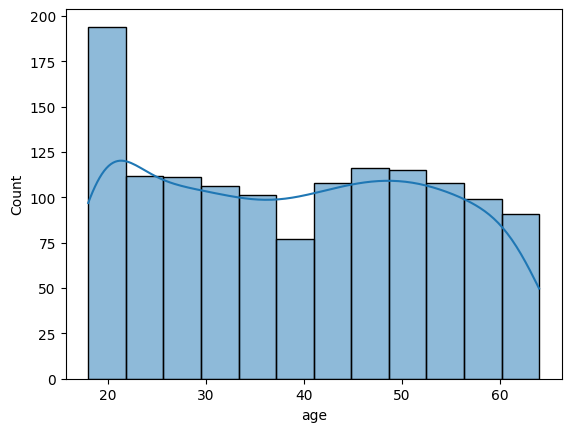

In [ ]:
sns.histplot(data["age"], kde=True)
plt.show()

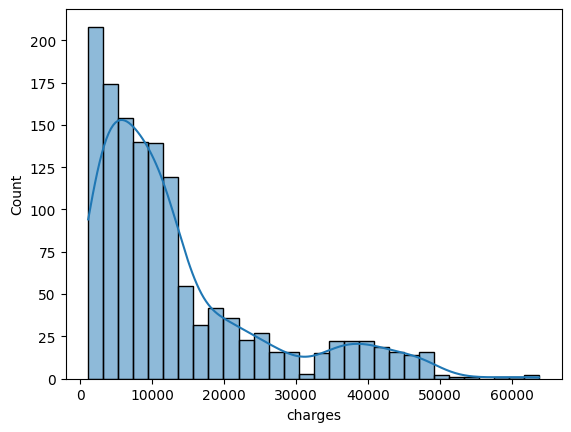

In [ ]:
sns.histplot(data["charges"], kde=True)
plt.show()

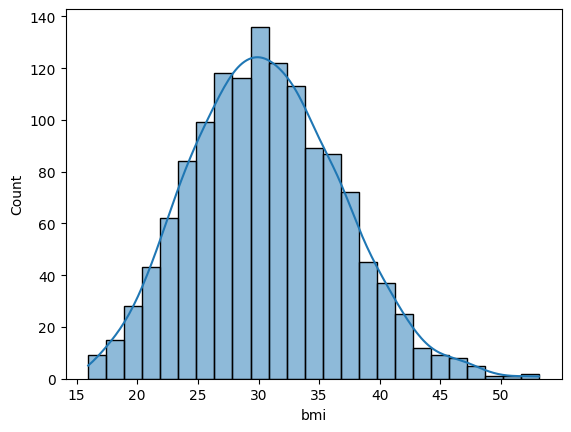

In [ ]:
sns.histplot(data["bmi"], kde=True)
plt.show()

In [ ]:
print(data["sex"].value_counts())
print(data["smoker"].value_counts())
print(data["region"].value_counts())

sex
male      676
female    662
Name: count, dtype: int64
smoker
no     1064
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


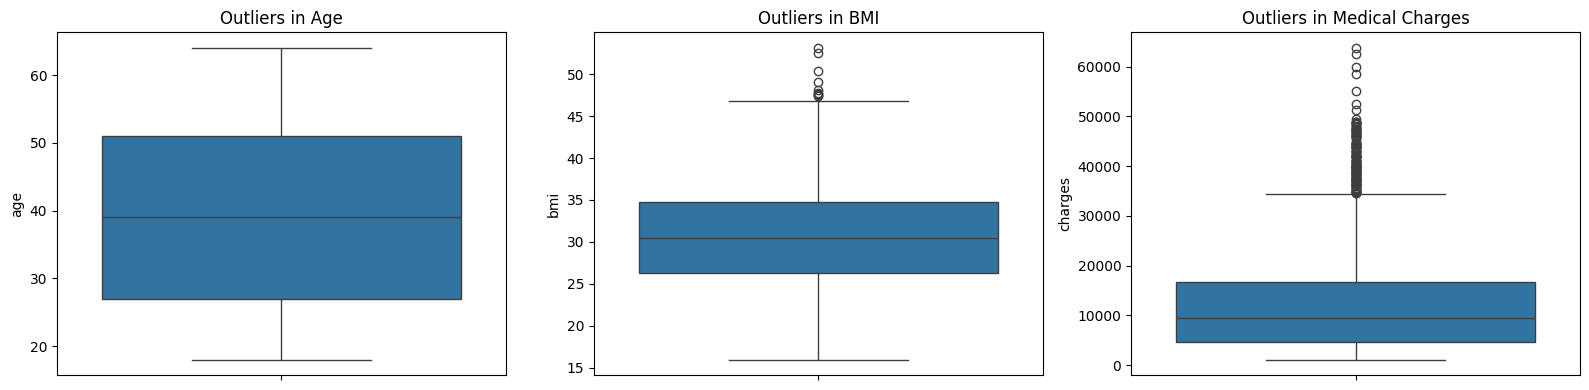

In [6]:
# Create box plots to identify potential outliers
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=data, y="age", ax=axes[0])
axes[0].set_title("Outliers in Age")

sns.boxplot(data=data, y="bmi", ax=axes[1])
axes[1].set_title("Outliers in BMI")

sns.boxplot(data=data, y="charges", ax=axes[2])
axes[2].set_title("Outliers in Medical Charges")

plt.tight_layout()
plt.show()

**PART 2**

**Research Question**

Is the proportion of smokers in the medical insurance dataset greater than 18%?

Null hypothesis: p = 0.18

alternative hypothesis: p > 0.18




**Significance Level**

The significance level is set at 0.05 (5%). This means that we accept a 5% risk of making a Type I error, which occurs when we reject the null hypothesis even though it is true. We will compare the p-value with the significance level to make our final decision.

This is a **Right tailed test and one tailed** because we want to determine whether the population of smokers is greater than 18%.

**Why is a Z-Test Appropriate?**

A one-proportion Z-test is appropriate because we want to compare the proportion of smokers in the dataset with the hypothesized population proportion of 18%. The sample size is sufficiently large, and the expected numbers of smokers and non-smokers under the null hypothesis should be at least 10 each. Therefore, the normal approximation can be used to perform the Z-test.

In [ ]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# Count the number of smokers
smokers = (data["smoker"] == "yes").sum()

# Count the total number of observations
n = data["smoker"].notna().sum()

# Calculate the observed smoker proportion
observed_proportion = smokers / n

# Define the hypothesized proportion
p0 = 0.18

# Perform a right-tailed one-proportion Z-test
z_stat, p_value = proportions_ztest(
    count=smokers,
    nobs=n,
    value=p0,
    alternative="larger"
)

print("Number of smokers:", smokers)
print("Total observations:", n)
print("Observed smoker proportion:", observed_proportion)
print("Z-statistic:", z_stat)
print("P-value:", p_value)

Number of smokers: 274
Total observations: 1338
Observed smoker proportion: 0.20478325859491778
Z-statistic: 2.246448584804205
P-value: 0.012337644658150439


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


**Conclusion**

The observed proportion of smokers in the dataset was **0.20478325859491778** . The calculated Z-statistic was **2.246448584804205**, and the p-value was **0.012337644658150439.**

At a significance level of 0.05, **we reject the null hypothesis.**

Therefore, the analysis **does not provide** sufficient statistical evidence to conclude that the population proportion of smokers is greater than 18%.

**PART 3**

**Research Question**

Do male and female customers have different average medical charges?

**Null Hypothesis**: The average medical charges of male and female customers are equal.

**Alternative Hypothesis:** The average medical charges of male and female customers are different.



**Type of Test**

A two-tailed test is appropriate because the research question asks whether the average medical charges of male and female customers are different.

**Significance Level**

The significance level is set at 0.05 (5%). We will compare the p-value with 0.05 to determine whether there is sufficient statistical evidence of a difference in average medical charges between male and female customers.

**Selection of the t-Test**

We will use an independent two-sample Welch's t-test because we are comparing the average medical charges of two independent groups: male customers and female customers.

Welch's t-test is appropriate because it does not require the variances of the two groups to be equal. It is a suitable choice when comparing the means of two independent groups.

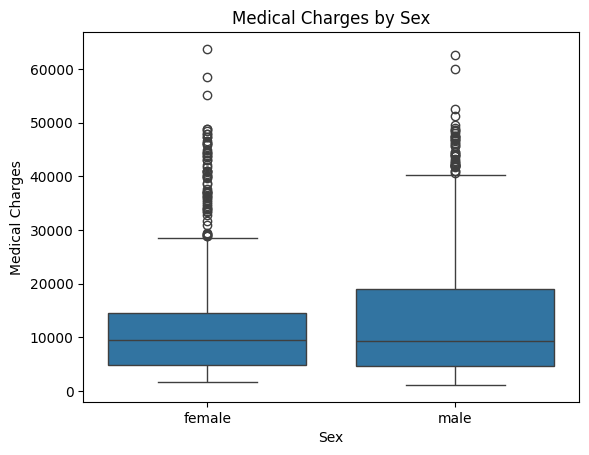

In [14]:

sns.boxplot(data=data, x="sex", y="charges")
plt.title("Medical Charges by Sex")
plt.xlabel("Sex")
plt.ylabel("Medical Charges")
plt.show()

In [ ]:
from scipy.stats import ttest_ind

# Separate medical charges for male and female customers
male_charges = data[data["sex"] == "male"]["charges"].dropna()
female_charges = data[data["sex"] == "female"]["charges"].dropna()

# Calculate and display the average medical charges for each group
print("Male average charges:", male_charges.mean())
print("Female average charges:", female_charges.mean())

# Perform an independent two-sample Welch's t-test to compare the group means
t_stat, p_value = ttest_ind(
    male_charges,
    female_charges,
    equal_var=False,       # Do not assume equal population variances
    alternative="two-sided"  # Test whether the population means are different
)

# Display the calculated t-statistic and p-value
print("T-statistic:", t_stat)
print("P-value:", p_value)

Male average charges: 13956.751177721893
Female average charges: 12569.578843835347
T-statistic: 2.1008878232359565
P-value: 0.03584101495601664


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Fail to reject the null hypothesis.


**Interpretation of Results**

The Welch's two-sample t-test was conducted to compare the average medical charges of male and female customers. The p-value was compared with the significance level of 0.05.

- If the p-value is less than 0.05, we reject the null hypothesis and conclude that there is statistically significant evidence of a difference in average medical charges between male and female customers. Since the p-value (0.0358) is less than the significance level of 0.05, we reject the null hypothesis.



**PART 4**

**Research Question**

Do smokers have higher average medical charges than non-smokers?


**Null hypothesis**

smokers = non smokers

**Alternative hypothesis**

Smokers > non- smokers

**Type of Test**

A **one-tailed (right-tailed) test** is appropriate because the research question specifically asks whether smokers have higher average medical charges than non-smokers. The alternative hypothesis predicts that the mean medical charges for smokers are greater than those for non-smokers.

**Significance level**

The significance level is set at 0.05. If the p-value is less than 0.05, we will reject the null hypothesis. Otherwise, we will fail to reject the null hypothesis.

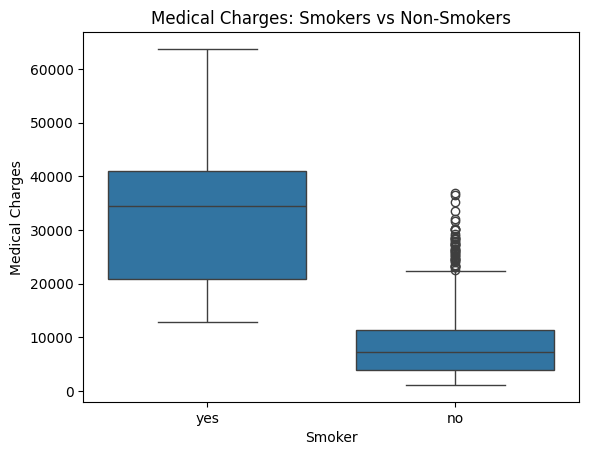

,count,mean,median,std
smoker,,,,
no,1064,8434.268298,7345.40530,5993.781819
yes,274,32050.231832,34456.34845,11541.547176


In [ ]:

sns.boxplot(data=data, x="smoker", y="charges")
plt.title("Medical Charges: Smokers vs Non-Smokers")
plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.show()

# Calculate summary statistics for each group
data.groupby("smoker")["charges"].agg(
    ["count", "mean", "median", "std"]
)

In [ ]:
from scipy.stats import ttest_ind

# Separate smokers and non-smokers
smoker_charges = data[data["smoker"] == "yes"]["charges"].dropna()
non_smoker_charges = data[data["smoker"] == "no"]["charges"].dropna()

# Perform a right-tailed Welch's t-test
t_stat, p_value = ttest_ind(
    smoker_charges,
    non_smoker_charges,
    equal_var=False,
    alternative="greater"
)

print("Smokers' Average Charges:", smoker_charges.mean())
print("Non-Smokers' Average Charges:", non_smoker_charges.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Smokers' Average Charges: 32050.23183153284
Non-Smokers' Average Charges: 8434.268297856204
T-statistic: 32.751887766341824
P-value: 2.94473222335849e-103


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is sufficient evidence that smokers have higher average medical charges than non-smokers.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence that smokers have higher average medical charges than non-smokers.")

Reject the null hypothesis.
There is sufficient evidence that smokers have higher average medical charges than non-smokers.


**Conclusion**

There is sufficient statistical evidence to conclude that smokers have higher average medical charges than non-smokers in this dataset. The average charges for smokers are substantially higher than those for non-smokers. However, statistical significance does not necessarily mean that smoking caused the difference in medical charges, because other factors may also influence medical costs.

PART 5


**Research Question**

Are average medical charges the same across all regions?

Null hypothesis : All the average medical charges for four regions are equal.

Alternative hypothesis: At least one average medical charge is different form other region.


If we perform separate t-tests for every pair of groups, the overall probability of making a Type I error may increase. ANOVA compares the means of all four groups using a single overall test.

A one-way ANOVA is appropriate because we want to compare the mean medical charges across four independent groups: northeast, northwest, southeast, and southwest. ANOVA tests whether there is evidence of a difference among the group means.

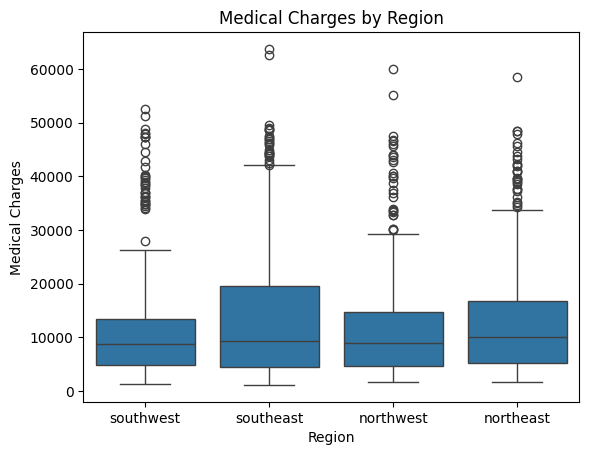

,count,mean,median,std
region,,,,
northeast,324,13406.384516,10057.652025,11255.803066
northwest,325,12417.575374,8965.795750,11072.276928
southeast,364,14735.411438,9294.131950,13971.098589
southwest,325,12346.937377,8798.593000,11557.179101


In [ ]:

sns.boxplot(data=data, x="region", y="charges")
plt.title("Medical Charges by Region")
plt.xlabel("Region")
plt.ylabel("Medical Charges")
plt.show()

# Calculate summary statistics for each region
data.groupby("region")["charges"].agg(
    ["count", "mean", "median", "std"]
)

**Anova Assumptions**

1. Independence: Each customer's observation should be independent of the observations of other customers.

2. Approximate Normality: The distribution of charges within each region should be approximately normal, or the sample size should be large enough for ANOVA to be reasonably robust.

3. Equal Variances: The population variances of all four regions should be approximately equal.

In [ ]:
from scipy.stats import f_oneway

# Separate medical charges for each region
northeast = data[data["region"] == "northeast"]["charges"].dropna()
northwest = data[data["region"] == "northwest"]["charges"].dropna()
southeast = data[data["region"] == "southeast"]["charges"].dropna()
southwest = data[data["region"] == "southwest"]["charges"].dropna()

# Perform one-way ANOVA
f_stat, p_value = f_oneway(
    northeast,
    northwest,
    southeast,
    southwest
)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 2.9696266935891193
P-value: 0.0308933560705201


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is sufficient evidence that average medical charges differ across regions.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence that average medical charges differ across regions.")

Reject the null hypothesis.
There is sufficient evidence that average medical charges differ across regions.


### ANOVA Results and Interpretation

A one-way ANOVA was conducted to determine whether average medical charges differ across the four regions: Northeast, Northwest, Southeast, and Southwest.

The F-statistic was **2.9696**, and the p-value was **0.0309**. Using a significance level of 0.05, the p-value is less than the significance level. Therefore, we reject the null hypothesis.

There is sufficient statistical evidence to conclude that average medical charges are not equal across all four regions. At least one region has a different population mean medical charge. However, ANOVA alone does not identify which specific regions differ. A Tukey HSD post-hoc test is needed to determine which pairs of regions have significantly different average charges.

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_result = pairwise_tukeyhsd(
    endog=data["charges"],
    groups=data["region"],
    alpha=0.05
)

print(tukey_result)

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1    group2   meandiff  p-adj    lower      upper   reject
-----------------------------------------------------------------
northeast northwest  -988.8091 0.7245 -3428.9343 1451.3161  False
northeast southeast  1329.0269 0.4745 -1044.9417 3702.9955  False
northeast southwest -1059.4471 0.6792 -3499.5723 1380.6781  False
northwest southeast  2317.8361 0.0583   -54.1994 4689.8716  False
northwest southwest    -70.638 0.9999 -2508.8826 2367.6066  False
southeast southwest -2388.4741 0.0477 -4760.5096  -16.4386   True
-----------------------------------------------------------------


### Tukey HSD Post-hoc Test Results and Interpretation

Since the one-way ANOVA showed a statistically significant result (F = 2.9696, p = 0.0309), a Tukey HSD post-hoc test was performed to identify which pairs of regions differed in their average medical charges.

The Tukey HSD results showed that only the **Southeast and Southwest** regions had a statistically significant difference in average medical charges (adjusted p-value = 0.0477). The estimated mean difference (Southwest minus Southeast) was approximately 2,388.47, indicating that the Southeast region had higher average charges than the Southwest region.

The other five regional comparisons were not statistically significant at the 0.05 significance level. Therefore, the post-hoc analysis suggests that the significant difference detected by ANOVA is associated with the Southeast–Southwest comparison. These results indicate an association with region, but they do not establish that region causes differences in medical charges.

ANOVA is an overall test that determines whether at least one group mean differs from the others, but it does not identify which specific groups differ. Therefore, a post-hoc test such as Tukey HSD is needed to compare individual pairs of groups while controlling the family-wise error rate.

**PART 6**

**Research Question**

Smoking status and geographical region are associated.

Null hypothesis: Region and smoking status are independent. There is no association between them.



Alternative hypothesis: Region and smoking status are not independent. There is an association between them.

In [12]:

# Create a contingency table to count smokers and non-smokers in each region
contingency_table = pd.crosstab(
    data["region"],  # Row variable: geographical region
    data["smoker"]   # Column variable: smoking status
)

# Display the contingency table
print(contingency_table)


smoker      no  yes
region             
northeast  257   67
northwest  267   58
southeast  273   91
southwest  267   58


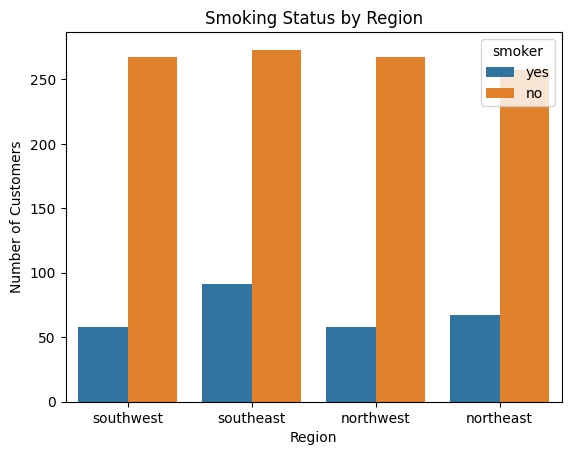

In [ ]:

sns.countplot(data=data, x="region", hue="smoker")

plt.title("Smoking Status by Region")
plt.xlabel("Region")
plt.ylabel("Number of Customers")
plt.show()

In [13]:

from scipy.stats import chi2_contingency

# Perform the Chi-square test of independence using the contingency table
chi2_stat, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Display the Chi-square statistic, degrees of freedom, and p-value
print("Chi-square Statistic:", chi2_stat)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

# Display the expected frequencies as a DataFrame
print("\nExpected Frequencies:")
print(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
))


Chi-square Statistic: 7.343477761407071
Degrees of Freedom: 3
P-value: 0.06171954839170541

Expected Frequencies:
smoker             no        yes
region                          
northeast  257.650224  66.349776
northwest  258.445441  66.554559
southeast  289.458894  74.541106
southwest  258.445441  66.554559


In [15]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant association between region and smoking status.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between region and smoking status.")

Fail to reject the null hypothesis.
There is insufficient evidence of an association between region and smoking status.


### Chi-square Test Results and Interpretation

A chi-square test of independence was conducted to examine whether there is an association between customers' region and smoking status.

The null hypothesis states that region and smoking status are independent, while the alternative hypothesis states that they are associated.

The chi-square statistic was **7.3435**, with **3 degrees of freedom** and a p-value of **0.0617**. At a significance level of 0.05, the p-value is greater than the significance level. Therefore, we fail to reject the null hypothesis.

There is insufficient statistical evidence at the 5% significance level to conclude that region and smoking status are associated in this dataset. This does not prove that the two variables are completely independent it means that the test did not find sufficient evidence of an association.

All expected cell frequencies were greater than 5, so the expected-frequency assumption for the chi-square test was satisfied.

In this test, there is no statistically significant evidence of an association between region and smoking status. We cannot conclude that a change in region affects smoking status or that smoking status determines a person's region.

**Part 7 — Type I and Type II Errors**

**Hypothesis Test Selected:** Do customers who smoke have higher average medical charges than customers who do not smoke?

**Type I Error:**

A Type I error would occur if the analyst concludes that insurance customers who smoke have higher average medical charges than customers who do not smoke, when in reality smokers do not have higher average charges in the population.

**Type II Error:**

A Type II error would occur if the analyst fails to find sufficient evidence that smokers have higher average medical charges than non-smokers, when in reality smokers do have higher average charges in the population.

**Conclusion for Our Test:**

In our test, the p-value was approximately 2.9447, which is less than the significance level of 0.05. Therefore, we rejected the null hypothesis and concluded that there is strong statistical evidence that smokers have higher average medical charges than non-smokers in this dataset. If this conclusion is incorrect, the possible error would be a Type I error.

**Part 8 — Understanding P-values**


In Part 3, I compared the average medical charges of male and female insurance customers. The p-value was approximately **0.03584**.

A p-value measures the probability of obtaining a result as extreme as, or more extreme than, the observed result, assuming that the null hypothesis is true. In this test, the p-value of 0.03584 means that if male and female customers have equal population mean medical charges, the probability of obtaining a difference at least as extreme as the observed difference is approximately 3.584%, under the assumptions of the test.

A p-value of 0.03 does **not** mean that there is a 3% probability that the null hypothesis is true. Instead, it describes how unusual the observed data would be if the null hypothesis were true. Since the p-value in our test (0.03584) is less than the significance level of 0.05, we reject the null hypothesis and conclude that there is statistically significant evidence of a difference in average medical charges between male and female customers.

**Part 9**

**Research Question**

Is the proportion of male insurance customers different from 50%?

Null hypothesis: The proportion of male customers is 50%, p = 0.50.


Alternative hypothesis: The proportion of male customers is different from 50%, p not equal to 0.50.

We will use a one-proportion Z-test because we are testing whether the proportion of male customers differs from a hypothesized population proportion of 50%.
- Test type: One-proportion Z-test
- Tail: Two-tailed, because we are checking for a proportion that is either higher or lower than 50%.
- Significance level: alpha = 0.05

Check assumptions
1. The variable sex is categorical, with male and female categories.
2. Each customer's observation should be independent.
3. The expected numbers of male and female customers under null hypothesis should be sufficiently large. Here, the expected count for each category is 0.50 * n is the total sample size.

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# Count the number of male customers
male_count = (data["sex"] == "male").sum()

# Count the total number of customers with a recorded sex
n = data["sex"].notna().sum()

# Calculate the observed proportion of male customers
observed_proportion = male_count / n

# Set the hypothesized proportion
p0 = 0.50

# Perform a two-tailed one-proportion Z-test
z_stat, p_value = proportions_ztest(
    count=male_count,
    nobs=n,
    value=p0,
    alternative="two-sided"
)

print("Number of male customers:", male_count)
print("Total customers:", n)
print("Observed proportion:", observed_proportion)
print("Observed percentage:", observed_proportion * 100)
print("Z-statistic:", z_stat)
print("P-value:", p_value)

Number of male customers: 676
Total customers: 1338
Observed proportion: 0.5052316890881914
Observed percentage: 50.52316890881914
Z-statistic: 0.3827575394277847
P-value: 0.7018995469169826


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("The proportion of male customers is significantly different from 50%.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence that the proportion of male customers differs from 50%.")

Fail to reject the null hypothesis.
There is insufficient evidence that the proportion of male customers differs from 50%.


The dataset contained 676 male customers out of 1,338 customers, giving an observed proportion of 0.5052 (50.52%). The calculated Z-statistic was 0.3828, and the p-value was 0.7019.

Since the p-value (0.7019) is greater than the significance level (0.05), we fail to reject the null hypothesis. There is insufficient statistical evidence to conclude that the proportion of male customers differs from 50% in the population represented by this dataset.

This result does not prove that the population proportion is exactly 50%; it indicates that the test did not find sufficient evidence of a difference.

Final Analysis


*   Medical Charges Across Regions: The ANOVA test showed a statistically significant difference in average medical charges across the four regions. Tukey's test found a significant difference only between the Southeast and Southwest regions.
*   Region and Smoking Status: The Chi-square test did not find sufficient evidence of a statistically significant association between region and smoking status at the 5% significance level.


*   Gender and Medical Charges: Male customers had higher average medical charges (13,956.75) than female customers (12,569.58). The difference was statistically significant at the 5% level.




